In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, unix_timestamp, hour, dayofweek, when
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import GeneralizedLinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark

# Spark başlat
spark = SparkSession.builder \
    .appName("NYC-Taxi-GLR") \
    .getOrCreate();

spark.sparkContext.setLogLevel("WARN")
print("✅ Spark başlatıldı.")

✅ Spark başlatıldı.


In [2]:
PARQUET_FILE = "/home/jovyan/work/data/yellow_tripdata_2024-01.parquet"
# 1. Veriyi oku
df = spark.read.parquet(PARQUET_FILE)

# 2. ÖNCE yeni sütunları oluştur
df = df.withColumn("trip_duration_min",
    (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60
)
df = df.withColumn("hour_of_day", hour("tpep_pickup_datetime"))
df = df.withColumn("day_of_week", dayofweek("tpep_pickup_datetime"))
df = df.withColumn("is_weekend", when(col("day_of_week") >= 6, 1).otherwise(0))
df = df.withColumn("is_rush_hour",
    when(
        ((col("hour_of_day") >= 7) & (col("hour_of_day") <= 9)) |
        ((col("hour_of_day") >= 17) & (col("hour_of_day") <= 19)), 1
    ).otherwise(0)
)
df = df.withColumn("is_airport",
    when((col("PULocationID") == 132) | (col("PULocationID") == 138), 1).otherwise(0)
)

# 3. SONRA filtrelemeyi yap (Artık trip_duration_min sütunu var)
df = df.filter(
    (col("trip_distance") > 0.5) &
    (col("total_amount") > 2.5) &
    (col("total_amount") < 150) &
    (col("passenger_count") > 0) &
    (col("tpep_pickup_datetime").isNotNull()) &
    (col("tpep_dropoff_datetime").isNotNull())
)
df = df.withColumn("trip_duration_min",
    (unix_timestamp("tpep_dropoff_datetime") - unix_timestamp("tpep_pickup_datetime")) / 60
)
df = df.filter(
    (col("trip_duration_min") > 1) &
    (col("trip_duration_min") < 120)
)

print(f"✅ Temizleme sonrası satır: {df.count()}")

✅ Temizleme sonrası satır: 2582120


In [3]:
# Feature vector oluştur
feature_cols = [
    "trip_distance",
    "trip_duration_min",
    "hour_of_day",
    "is_weekend",
    "is_rush_hour",
    "is_airport",
    "passenger_count"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df = assembler.transform(df)

# Train/Test split
train_df, test_df = df.randomSplit([0.75, 0.25], seed=42)
print(f"✅ Eğitim seti: {train_df.count()} satır")
print(f"✅ Test seti: {test_df.count()} satır")

✅ Eğitim seti: 1936586 satır
✅ Test seti: 645534 satır


In [4]:
from pyspark.ml.feature import StandardScaler
from pyspark.ml import Pipeline

scaler = StandardScaler(inputCol="features", outputCol="features_scaled", withStd=True, withMean=False)
scaler_model = scaler.fit(train_df)

train_scaled = scaler_model.transform(train_df)
test_scaled = scaler_model.transform(test_df)

print("✅ Feature'lar normalize edildi.")

✅ Feature'lar normalize edildi.


In [6]:
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment(experiment_id="1")

evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
evaluator_mae  = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
evaluator_r2   = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")

with mlflow.start_run(run_name="GLR_Regressor"):
    
    glr = GeneralizedLinearRegression(
        featuresCol="features_scaled",
        labelCol="total_amount",
        family="gaussian",
        link="identity",
        maxIter=50,
        regParam=0.01
    )
    
    glr_model = glr.fit(train_scaled)
    predictions = glr_model.transform(test_scaled)
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae  = evaluator_mae.evaluate(predictions)
    r2   = evaluator_r2.evaluate(predictions)
    
    mlflow.log_param("model_type", "GeneralizedLinearRegression")
    mlflow.log_param("family", "gaussian")
    mlflow.log_param("link", "identity")
    mlflow.log_param("maxIter", 50)
    mlflow.log_metric("RMSE", rmse)
    mlflow.log_metric("MAE", mae)
    mlflow.log_metric("R2", r2)
    mlflow.spark.log_model(glr_model, "glr_model")
    
    print(f"✅ GLR → RMSE: {rmse:.3f}, MAE: {mae:.3f}, R²: {r2:.3f}")

✅ GLR → RMSE: 10.284, MAE: 4.556, R²: 0.749
🏃 View run GLR_Regressor at: http://mlflow-server:5001/#/experiments/1/runs/37e48671b5254624a1ce808e6d66e14d
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


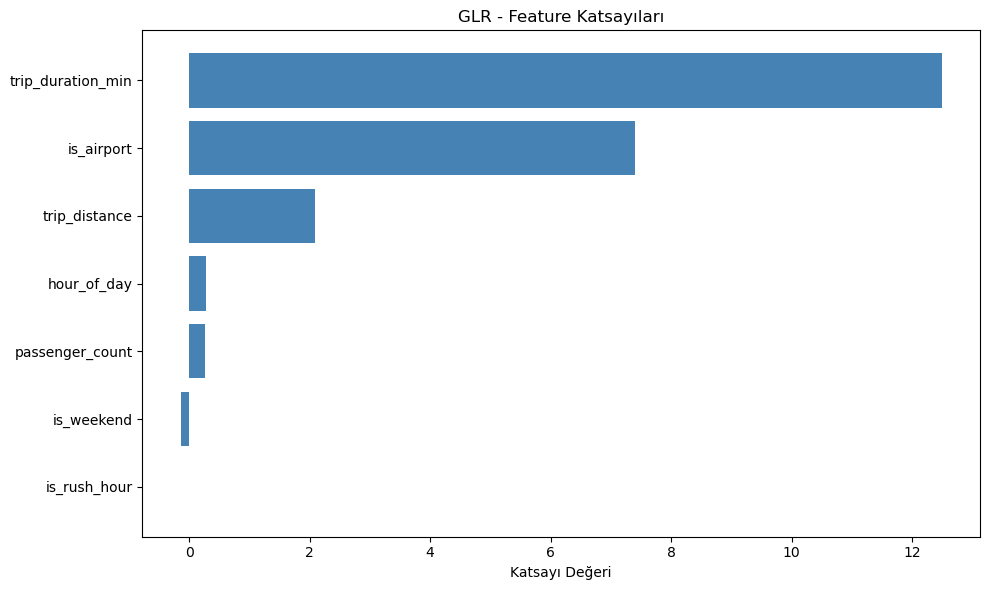

✅ Katsayı grafiği kaydedildi.


In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# GLR Katsayıları (Feature Importance yerine)
coefficients = glr_model.coefficients.toArray()
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": coefficients
})
importance_df = importance_df.reindex(importance_df["Coefficient"].abs().sort_values().index)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Coefficient"], color="steelblue")
plt.title("GLR - Feature Katsayıları")
plt.xlabel("Katsayı Değeri")
plt.tight_layout()
plt.savefig("/home/jovyan/work/data/glr_coefficients.png")
plt.show()
print("✅ Katsayı grafiği kaydedildi.")

<module 'matplotlib.pyplot' from '/opt/conda/lib/python3.11/site-packages/matplotlib/pyplot.py'>

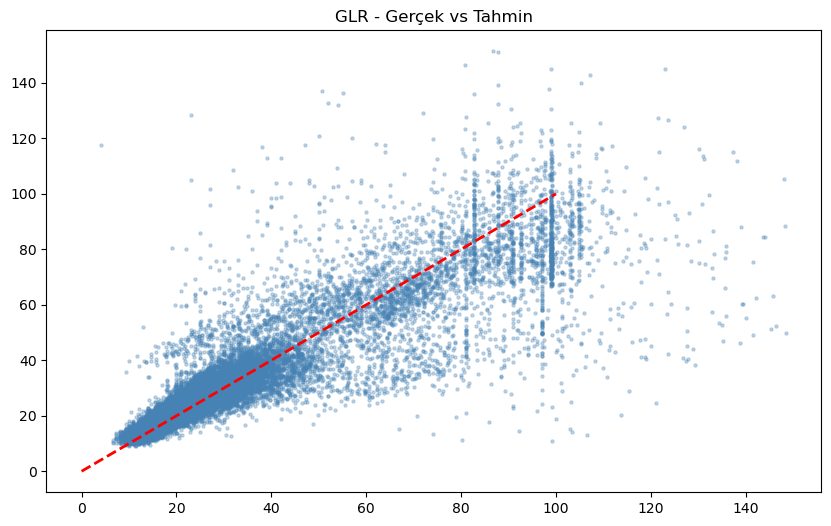

In [8]:
# Gerçek vs Tahmin scatter plot
sample = predictions.select("total_amount", "prediction") \
    .sample(fraction=0.05) \
    .toPandas()

plt.figure(figsize=(10, 6))
plt.scatter(sample["total_amount"], sample["prediction"], alpha=0.3, s=5, color="steelblue")
plt.plot([0, 100], [0, 100], color="red", linewidth=2, linestyle="--", label="Mükemmel Tahmin")
plt.title("GLR - Gerçek vs Tahmin")
plt